<a href="https://colab.research.google.com/github/emna378/ids-explainability-audit/blob/emna/01_donnees_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, random, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = "/content/drive/MyDrive/dataset"
os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)

# 1 — Charger les données

In [ ]:
tr = pd.read_csv(f"{DATA_DIR}/UNSW_NB15_training-set.csv")
te = pd.read_csv(f"{DATA_DIR}/UNSW_NB15_testing-set.csv")
df = pd.concat([tr, te], ignore_index=True)     # on colle les deux fichiers l'un sous l'autre
print("Taille (lignes, colonnes) :", df.shape)
print(df.head())

Taille (lignes, colonnes) : (257673, 45)
   id       dur proto service state  spkts  dpkts  sbytes  dbytes  \
0   1  0.000011   udp       -   INT      2      0     496       0   
1   2  0.000008   udp       -   INT      2      0    1762       0   
2   3  0.000005   udp       -   INT      2      0    1068       0   
3   4  0.000006   udp       -   INT      2      0     900       0   
4   5  0.000010   udp       -   INT      2      0    2126       0   

          rate  ...  ct_dst_sport_ltm  ct_dst_src_ltm  is_ftp_login  \
0   90909.0902  ...                 1               2             0   
1  125000.0003  ...                 1               2             0   
2  200000.0051  ...                 1               3             0   
3  166666.6608  ...                 1               3             0   
4  100000.0025  ...                 1               3             0   

   ct_ftp_cmd  ct_flw_http_mthd  ct_src_ltm  ct_srv_dst  is_sm_ips_ports  \
0           0                 0          

# 2. Explorer les données









In [ ]:
print(df.dtypes.value_counts())
print("Normal (0) vs attaque (1) :")
print(df["label"].value_counts())
print("Part d'attaques :", round(df["label"].mean(), 3))
print()


if "attack_cat" in df.columns:
    print(df["attack_cat"].value_counts())
elif 'family' in globals():
    print("Familles d'attaques (depuis la variable 'family') :")
    print(family.value_counts())
else:
    print("La colonne 'attack_cat' n'est pas disponible dans le DataFrame.")

print()
print(df[["proto", "service", "state"]].nunique())   # nombre de valeurs différentes

int64      30
float64    11
object      4
Name: count, dtype: int64
Normal (0) vs attaque (1) :
label
1    164673
0     93000
Name: count, dtype: int64
Part d'attaques : 0.639

attack_cat
Normal            93000
Generic           58871
Exploits          44525
Fuzzers           24246
DoS               16353
Reconnaissance    13987
Analysis           2677
Backdoor           2329
Shellcode          1511
Worms               174
Name: count, dtype: int64

proto      133
service     13
state       11
dtype: int64


# 3 — Nettoyer les données

In [ ]:
family = df["attack_cat"].copy()
df = df.drop(columns=["id", "attack_cat"])
df = df.replace([np.inf, -np.inf], np.nan)

n_manquantes = int(df.isna().sum().sum())
n_doublons = int(df.duplicated().sum())
print("Valeurs manquantes :", n_manquantes)
print("Lignes en double   :", n_doublons, "sur", len(df))

Valeurs manquantes : 0
Lignes en double   : 103575 sur 257673


## on enlève les doublons

In [ ]:
df = df.drop_duplicates()
family = family.loc[df.index]
print("Taille après nettoyage :", df.shape)

Taille après nettoyage : (154098, 43)


# 4 — Découper en entraînement, validation et test

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["label"])
y = df["label"]

# 1) on met 10 % de côté pour le TEST (on n'y touchera qu'à la fin)
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

# 2) on coupe le reste : 90 % entraînement, 10 % validation (= 60 % et 20 % du total)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.10, stratify=y_tmp, random_state=SEED)
for nom, part in [("entraînement", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{nom:13s}: {len(part):7d} flux | part d'attaques = {part.mean():.3f}")

entraînement :  110950 flux | part d'attaques = 0.444
validation   :   12328 flux | part d'attaques = 0.444
test         :   30820 flux | part d'attaques = 0.444


# 5 — Préparer les variables

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

cat_cols = ["proto", "service", "state"]
num_cols = [c for c in X_train.columns if c not in cat_cols]
print(len(num_cols), "colonnes numériques,", len(cat_cols), "colonnes de texte")

# Pour la régression logistique : numériques mises à la même échelle + texte en 0/1
prep_lin = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])

# Pour les arbres : numériques inchangées + texte remplacé par un numéro
prep_tree = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols)])

39 colonnes numériques, 3 colonnes de texte


# 6 — Mesurer et entraîner la baseline

In [ ]:
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score)
def evaluate(y_true, proba, thr=0.5, name="modèle", verbose=True):
    """Calcule les métriques pour un seuil donné. proba = probabilité d'attaque (0 à 1)."""
    pred = (proba >= thr).astype(int)
    res = {"modèle": name, "seuil": round(float(thr), 3),
           "PR-AUC": round(average_precision_score(y_true, proba), 4),
           "précision": round(precision_score(y_true, pred), 4),
           "rappel": round(recall_score(y_true, pred), 4),
           "F1": round(f1_score(y_true, pred), 4)}
    if verbose:
        print(f"=== {name} (seuil = {thr:.2f}) ===")
        print("Matrice [[vrais normaux, fausses alertes], [attaques ratées, attaques détectées]]")
        print(confusion_matrix(y_true, pred))
        print(classification_report(y_true, pred, digits=3, target_names=["normal", "attaque"]))
        print("PR-AUC :", res["PR-AUC"])
    return res
def best_threshold(y_true, proba):
    """Seuil qui donne le meilleur F1. À appeler UNIQUEMENT sur la validation."""
    pr, rc, th = precision_recall_curve(y_true, proba)
    f1 = 2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12)
    return float(th[np.argmax(f1)])

 La baseline : régression logistique

In [ ]:
from sklearn.linear_model import LogisticRegression
baseline = Pipeline([
    ("prep", prep_lin),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))])
t0 = time.time()
baseline.fit(X_train, y_train)
print("Temps d'entraînement :", round(time.time() - t0, 1), "s")
p_val_base = baseline.predict_proba(X_val)[:, 1]
evaluate(y_val, p_val_base, thr=0.5, name="Baseline (seuil 0.5)")

Temps d'entraînement : 11.7 s
=== Baseline (seuil 0.5) (seuil = 0.50) ===
Matrice [[vrais normaux, fausses alertes], [attaques ratées, attaques détectées]]
[[5203 1655]
 [ 261 5209]]
              precision    recall  f1-score   support

      normal      0.952     0.759     0.845      6858
     attaque      0.759     0.952     0.845      5470

    accuracy                          0.845     12328
   macro avg      0.856     0.855     0.845     12328
weighted avg      0.866     0.845     0.845     12328

PR-AUC : 0.9275


{'modèle': 'Baseline (seuil 0.5)',
 'seuil': 0.5,
 'PR-AUC': np.float64(0.9275),
 'précision': 0.7589,
 'rappel': 0.9523,
 'F1': 0.8447}

# Étape 7 — Entraîner la forêt aléatoire et XGBoost

 entraîner les deux modèles principaux, d'abord simplement, puis en cherchant de
meilleurs réglages.
### 7a. Premier essai : forêt avec les réglages par défaut

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf_simple = Pipeline([
    ("prep", prep_tree),
    ("clf", RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1))])
t0 = time.time()
rf_simple.fit(X_train, y_train)
print("Temps d'entraînement :", round(time.time() - t0, 1), "s")
p_val_rf0 = rf_simple.predict_proba(X_val)[:, 1]
evaluate(y_val, p_val_rf0, thr=0.5, name="Forêt aléatoire, réglages par défaut")

Temps d'entraînement : 37.5 s
=== Forêt aléatoire, réglages par défaut (seuil = 0.50) ===
Matrice [[vrais normaux, fausses alertes], [attaques ratées, attaques détectées]]
[[6396  462]
 [ 559 4911]]
              precision    recall  f1-score   support

      normal      0.920     0.933     0.926      6858
     attaque      0.914     0.898     0.906      5470

    accuracy                          0.917     12328
   macro avg      0.917     0.915     0.916     12328
weighted avg      0.917     0.917     0.917     12328

PR-AUC : 0.9743


{'modèle': 'Forêt aléatoire, réglages par défaut',
 'seuil': 0.5,
 'PR-AUC': np.float64(0.9743),
 'précision': 0.914,
 'rappel': 0.8978,
 'F1': 0.9058}

### 7b. Chercher de meilleurs réglages (hyperparamètres)

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from xgboost import XGBClassifier
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
# Pour gagner du temps, on cherche les bons réglages sur un sous-échantillon de l'ENTRAÎNEMENT
n_sub = min(50000, int(len(X_train) * 0.8))
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=n_sub,
                                      stratify=y_train, random_state=SEED)
# ---------- Forêt aléatoire ---------
rf = Pipeline([("prep", prep_tree),
               ("clf", RandomForestClassifier(random_state=SEED, n_jobs=-1))])
rf_grid = {"clf__n_estimators": [200, 400], "clf__max_depth": [10, 20, None],
           "clf__min_samples_leaf": [1, 2, 5], "clf__max_features": ["sqrt", 0.5]}
rf_search = RandomizedSearchCV(rf, rf_grid, n_iter=8, scoring="average_precision",
                               cv=cv, random_state=SEED, n_jobs=-1)
t0 = time.time(); rf_search.fit(X_sub, y_sub); t_tune_rf = time.time() - t0
print("Meilleurs réglages RF :", rf_search.best_params_)
# On repart d'un modèle vierge, entraîné cette fois sur TOUT l'entraînement
best_rf = clone(rf_search.best_estimator_)
t0 = time.time(); best_rf.fit(X_train, y_train); t_fit_rf = time.time() - t0
t0 = time.time(); p_val_rf = best_rf.predict_proba(X_val)[:, 1]; t_pred_rf = time.time() - t0
json.dump(rf_search.best_params_, open("results/best_params_rf.json", "w"))
# ---------- XGBoost ---------
xgb = Pipeline([("prep", prep_tree),
                ("clf", XGBClassifier(tree_method="hist", eval_metric="aucpr",
                                      random_state=SEED, n_jobs=-1))])
xgb_grid = {"clf__n_estimators": [200, 400], "clf__max_depth": [3, 5, 7],
            "clf__learning_rate": [0.03, 0.1, 0.2], "clf__subsample": [0.7, 1.0],
            "clf__colsample_bytree": [0.7, 1.0]}
xgb_search = RandomizedSearchCV(xgb, xgb_grid, n_iter=8, scoring="average_precision",
                                cv=cv, random_state=SEED, n_jobs=-1)
t0 = time.time(); xgb_search.fit(X_sub, y_sub); t_tune_xgb = time.time() - t0
print("Meilleurs réglages XGBoost :", xgb_search.best_params_)
best_xgb = clone(xgb_search.best_estimator_)
t0 = time.time(); best_xgb.fit(X_train, y_train); t_fit_xgb = time.time() - t0
t0 = time.time(); p_val_xgb = best_xgb.predict_proba(X_val)[:, 1]; t_pred_xgb = time.time() - t0
json.dump(xgb_search.best_params_, open("results/best_params_xgb.json", "w"))

Meilleurs réglages RF : {'clf__n_estimators': 400, 'clf__min_samples_leaf': 2, 'clf__max_features': 0.5, 'clf__max_depth': 20}
Meilleurs réglages XGBoost : {'clf__subsample': 0.7, 'clf__n_estimators': 400, 'clf__max_depth': 7, 'clf__learning_rate': 0.03, 'clf__colsample_bytree': 0.7}


# Étape 8 — Comparer les trois modèles sur la validation

In [ ]:
lignes = []
for nom, p, t_fit, t_pred in [
        ("Baseline (régression logistique)", p_val_base, None, None),
        ("Forêt aléatoire", p_val_rf, t_fit_rf, t_pred_rf),
        ("XGBoost", p_val_xgb, t_fit_xgb, t_pred_xgb)]:
    seuil = best_threshold(y_val, p)            # seuil choisi sur la validation
    r = evaluate(y_val, p, seuil, nom, verbose=False)
    r["temps entraînement (s)"] = None if t_fit is None else round(t_fit, 1)
    r["temps prédiction (s)"] = None if t_pred is None else round(t_pred, 2)
    lignes.append(r)
tableau_val = pd.DataFrame(lignes).set_index("modèle")
print(tableau_val)
tableau_val.to_csv("results/comparaison_validation.csv")
print("\nRéférence PR-AUC d'un modèle au hasard = part d'attaques =", round(y_val.mean(), 3))

                                  seuil  PR-AUC  précision  rappel      F1  \
modèle                                                                       
Baseline (régression logistique)  0.218  0.9275     0.7400  0.9943  0.8485   
Forêt aléatoire                   0.477  0.9774     0.9113  0.9055  0.9084   
XGBoost                           0.442  0.9769     0.8974  0.9165  0.9068   

                                  temps entraînement (s)  temps prédiction (s)  
modèle                                                                          
Baseline (régression logistique)                     NaN                   NaN  
Forêt aléatoire                                    396.1                  0.44  
XGBoost                                             12.5                  0.16  

Référence PR-AUC d'un modèle au hasard = part d'attaques = 0.444


# Étape 9 — Quelles variables comptent ? (sur la validation)

repérer les variables dominantes sans toucher au test, pour préparer l'audit. Deux
mesures suffisent ici.

In [ ]:
from sklearn.inspection import permutation_importance
feat_names = num_cols + cat_cols                # même ordre que la sortie de prep_tree
rf_model = best_rf.named_steps["clf"]           # la forêt seule, sans le prétraitement
Xt_val = best_rf.named_steps["prep"].transform(X_val)    # validation prétraitée (tableau NumPy)
mdi = pd.Series(rf_model.feature_importances_, index=feat_names)       # importance interne
perm = permutation_importance(rf_model, Xt_val, y_val, scoring="average_precision",
                              n_repeats=5, random_state=SEED, n_jobs=-1)
perm_val = pd.Series(perm.importances_mean, index=feat_names)          # importance par permutation
top = pd.DataFrame({"MDI": mdi, "Permutation": perm_val}).sort_values("Permutation", ascending=False)
print(top.head(10).round(4))
top.head(10).to_csv("results/top10_importances_validation.csv")

                   MDI  Permutation
sttl            0.3061       0.2078
ct_dst_src_ltm  0.0810       0.0348
dbytes          0.0231       0.0135
ct_state_ttl    0.1550       0.0112
service         0.0157       0.0091
sbytes          0.0345       0.0086
ct_srv_dst      0.0455       0.0073
dmean           0.0190       0.0067
smean           0.0284       0.0062
dttl            0.0368       0.0052


# Étape 10 — Audit de plausibilité : le modèle a-t-il appris de vraies attaques ?

 pour chacune des 10 variables les plus importantes, répondre honnêtement à la
question : « un vrai trafic malveillant produit-il naturellement cette valeur, ou est-ce un artefact de
la façon dont le jeu a été construit ? »

In [ ]:
for v in ["sttl", "ct_dst_src_ltm"]:              # À REMPLACER par vos variables du top 10
    print(f"----- {v} -----")
    print(df.groupby("label")[v].describe()[["mean", "min", "50%", "max"]].round(2))
    # À quel point cette variable, à elle seule, sépare-t-elle les classes ?
    top_vals = df[v].value_counts().head(5).index
    print(pd.crosstab(df[v].where(df[v].isin(top_vals), -1), df["label"], normalize="index").round(2))

----- sttl -----
         mean  min    50%    max
label                           
0       93.12  0.0   31.0  255.0
1      200.64  0.0  254.0  255.0
label     0     1
sttl             
-1     0.83  0.17
 0     0.98  0.02
 1     1.00  0.00
 31    1.00  0.00
 62    0.24  0.76
 254   0.32  0.68
----- ct_dst_src_ltm -----
       mean  min  50%   max
label                      
0      3.60  1.0  2.0  63.0
1      4.24  1.0  1.0  65.0
label              0     1
ct_dst_src_ltm            
-1              0.57  0.43
 1              0.40  0.60
 2              0.64  0.36
 3              0.74  0.26
 4              0.75  0.25
 5              0.76  0.24


# Étape 11 — Ablation : que reste-t-il sans les variables suspectes ?

In [ ]:
suspect = ["sttl", "ct_state_ttl"]              # À DÉCIDER avec vos résultats et votre audit
def build_model(kind, num, cat, params):
    """Reconstruit un modèle avec les mêmes réglages, sur un ensemble de colonnes donné."""
    prep = ColumnTransformer([
        ("num", "passthrough", num),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat)])
    if kind == "rf":
        clf = RandomForestClassifier(random_state=SEED, n_jobs=-1)
    else:
        clf = XGBClassifier(tree_method="hist", eval_metric="aucpr", random_state=SEED, n_jobs=-1)
    return Pipeline([("prep", prep), ("clf", clf)]).set_params(**params)
num_a = [c for c in num_cols if c not in suspect]
cols_a = num_a + cat_cols
rf_abl = build_model("rf", num_a, cat_cols, rf_search.best_params_)
rf_abl.fit(X_train[cols_a], y_train)
p_val_abl = rf_abl.predict_proba(X_val[cols_a])[:, 1]
r_full = evaluate(y_val, p_val_rf, best_threshold(y_val, p_val_rf), "RF complète", verbose=False)
nom_abl = "RF sans " + "+".join(suspect)
r_abl = evaluate(y_val, p_val_abl, best_threshold(y_val, p_val_abl), nom_abl, verbose=False)
tab_abl = pd.DataFrame([r_full, r_abl]).set_index("modèle")
tab_abl.loc["différence"] = tab_abl.iloc[1][["PR-AUC", "précision", "rappel", "F1"]] - \
                            tab_abl.iloc[0][["PR-AUC", "précision", "rappel", "F1"]]
print(tab_abl)
tab_abl.to_csv("results/ablation_validation.csv")

                           seuil  PR-AUC  précision  rappel      F1
modèle                                                             
RF complète                0.477  0.9774     0.9113  0.9055  0.9084
RF sans sttl+ct_state_ttl  0.489  0.9775     0.9198  0.9013  0.9104
différence                   NaN  0.0001     0.0085 -0.0042  0.0020


# Étape 12 — GEL puis évaluation finale sur le test

In [ ]:
# ===== Seuils choisis sur la VALIDATION, puis figés =====
seuils = {"Baseline": best_threshold(y_val, p_val_base),
          "Forêt aléatoire": best_threshold(y_val, p_val_rf),
          "XGBoost": best_threshold(y_val, p_val_xgb)}
json.dump(seuils, open("results/seuils_figes.json", "w"))
# ===== UNE SEULE évaluation sur le test =====
p_test = {"Baseline": baseline.predict_proba(X_test)[:, 1],
          "Forêt aléatoire": best_rf.predict_proba(X_test)[:, 1],
          "XGBoost": best_xgb.predict_proba(X_test)[:, 1]}
lignes = [evaluate(y_test, p_test[nom], seuils[nom], nom) for nom in p_test]
tableau_test = pd.DataFrame(lignes).set_index("modèle")
print(tableau_test)
tableau_test.to_csv("results/resultats_test_final.csv")
# Courbes précision-rappel
plt.figure(figsize=(6, 4.5))
for nom, p in p_test.items():
    pr, rc, _ = precision_recall_curve(y_test, p)
    plt.plot(rc, pr, label=nom)
plt.axhline(y_test.mean(), color="gray", ls="--", label="hasard")
plt.xlabel("Rappel"); plt.ylabel("Précision"); plt.legend()
plt.title("Courbes précision-rappel (test)")
plt.savefig("figures/courbes_pr_test.png", dpi=150, bbox_inches="tight"); plt.close()
# Charge d'alertes pour la forêt
pred_rf = (p_test["Forêt aléatoire"] >= seuils["Forêt aléatoire"]).astype(int)
print("Alertes pour 10 000 flux :", round(pred_rf.mean() * 10000))
print("Part de vraies attaques parmi les alertes :", round(y_test.to_numpy()[pred_rf == 1].mean(), 3))


=== Baseline (seuil = 0.22) ===
Matrice [[vrais normaux, fausses alertes], [attaques ratées, attaques détectées]]
[[12320  4825]
 [   75 13600]]
              precision    recall  f1-score   support

      normal      0.994     0.719     0.834     17145
     attaque      0.738     0.995     0.847     13675

    accuracy                          0.841     30820
   macro avg      0.866     0.857     0.841     30820
weighted avg      0.880     0.841     0.840     30820

PR-AUC : 0.9353
=== Forêt aléatoire (seuil = 0.48) ===
Matrice [[vrais normaux, fausses alertes], [attaques ratées, attaques détectées]]
[[15953  1192]
 [ 1265 12410]]
              precision    recall  f1-score   support

      normal      0.927     0.930     0.928     17145
     attaque      0.912     0.907     0.910     13675

    accuracy                          0.920     30820
   macro avg      0.919     0.919     0.919     30820
weighted avg      0.920     0.920     0.920     30820

PR-AUC : 0.9776
=== XGBoost (seui

# Étape 13 — Importances globales : trois mesures, un tableau, SHAP

In [ ]:
import shap
from scipy.stats import spearmanr
Xt_test = best_rf.named_steps["prep"].transform(X_test)       # test prétraité
perm_t = permutation_importance(rf_model, Xt_test, y_test, scoring="average_precision",
                                n_repeats=5, random_state=SEED, n_jobs=-1)
n_ech = min(2000, len(Xt_test))
idx = np.random.RandomState(SEED).choice(len(Xt_test), n_ech, replace=False)
sample = pd.DataFrame(Xt_test[idx], columns=feat_names)       # au plus 2 000 flux du test
sv = shap.TreeExplainer(rf_model).shap_values(sample)
print("Forme des valeurs SHAP :", np.shape(sv))
if isinstance(sv, list):                         # anciennes versions : liste [classe 0, classe 1]
    sv_att = sv[1]
elif sv.ndim == 3:                               # (flux, variables, classes)
    sv_att = sv[:, :, 1]
else:
    sv_att = sv
compar = pd.DataFrame({"MDI": mdi,
                       "Permutation": pd.Series(perm_t.importances_mean, index=feat_names),
                       "SHAP": pd.Series(np.abs(sv_att).mean(axis=0), index=feat_names)})
print(compar.sort_values("SHAP", ascending=False).head(10).round(4))
rangs = compar.rank(ascending=False)
print("\nAccord entre les classements (Spearman) :")
print(rangs.corr(method="spearman").round(2))
compar.to_csv("results/importances_test.csv")
shap.summary_plot(sv_att, sample, max_display=15, show=False)
plt.savefig("figures/shap_resume.png", dpi=150, bbox_inches="tight"); plt.close()

Forme des valeurs SHAP : (2000, 42, 2)
                   MDI  Permutation    SHAP
sttl            0.3061       0.2026  0.2241
ct_state_ttl    0.1550       0.0112  0.0779
ct_dst_src_ltm  0.0810       0.0348  0.0545
dttl            0.0368       0.0050  0.0419
ct_srv_dst      0.0455       0.0069  0.0253
dbytes          0.0231       0.0133  0.0232
service         0.0157       0.0083  0.0184
smean           0.0284       0.0067  0.0171
dmean           0.0190       0.0060  0.0160
sbytes          0.0345       0.0089  0.0154

Accord entre les classements (Spearman) :
              MDI  Permutation  SHAP
MDI          1.00         0.83  0.88
Permutation  0.83         1.00  0.92
SHAP         0.88         0.92  1.00


/tmp/ipykernel_657/162014010.py:25: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_att, sample, max_display=15, show=False)


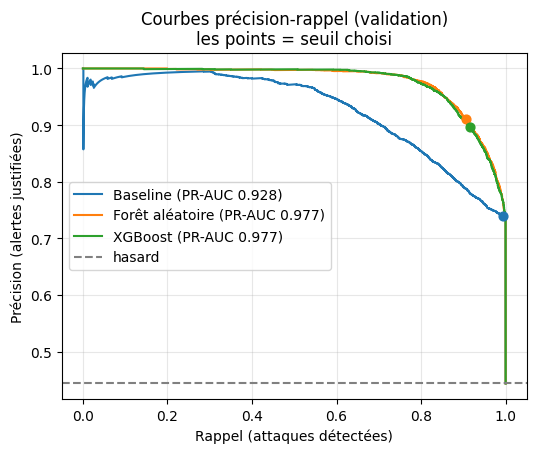

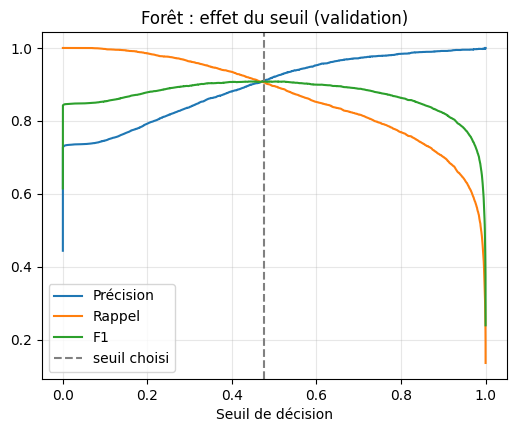

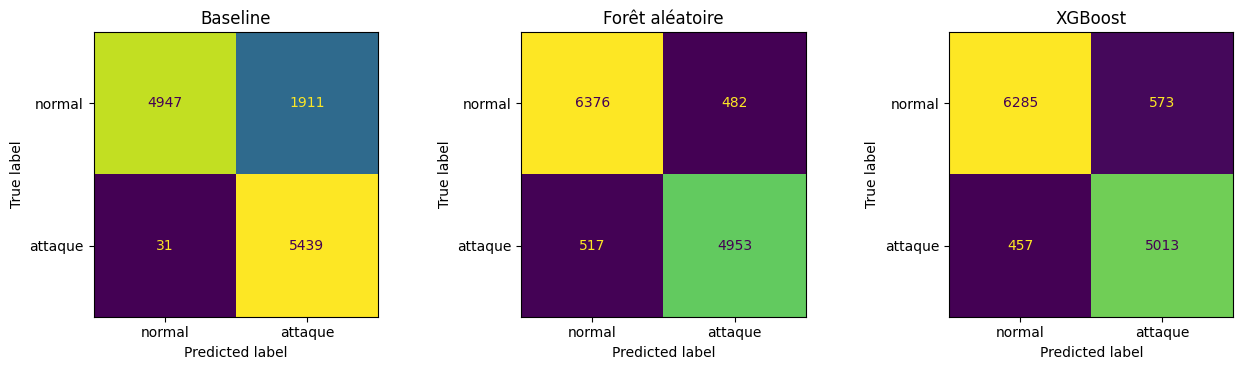

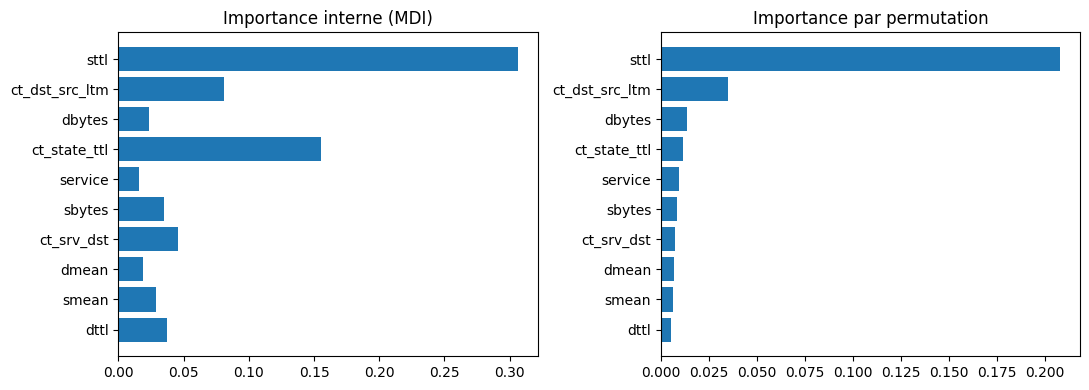

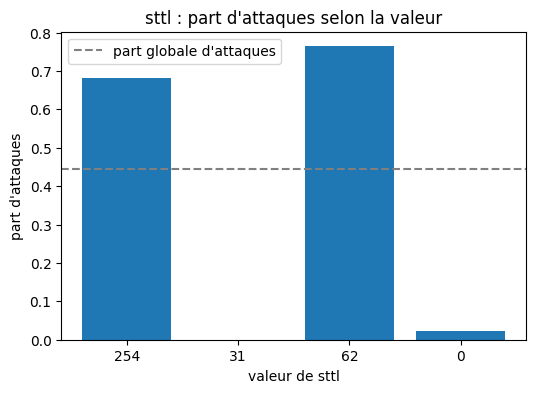

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

modeles_val = {"Baseline": p_val_base, "Forêt aléatoire": p_val_rf, "XGBoost": p_val_xgb}

# ---- Graphique 1 : courbes précision-rappel (validation) ----
plt.figure(figsize=(6, 4.5))
for nom, p in modeles_val.items():
    pr, rc, _ = precision_recall_curve(y_val, p)
    plt.plot(rc, pr, label=f"{nom} (PR-AUC {average_precision_score(y_val, p):.3f})")
    pred = (p >= best_threshold(y_val, p)).astype(int)
    plt.scatter([recall_score(y_val, pred)], [precision_score(y_val, pred)], s=40, zorder=3)
plt.axhline(y_val.mean(), color="gray", ls="--", label="hasard")
plt.xlabel("Rappel (attaques détectées)"); plt.ylabel("Précision (alertes justifiées)")
plt.title("Courbes précision-rappel (validation)\nles points = seuil choisi")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("figures/pr_validation.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- Graphique 2 : effet du seuil sur la forêt ----
pr, rc, th = precision_recall_curve(y_val, p_val_rf)
f1 = 2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12)
plt.figure(figsize=(6, 4.5))
plt.plot(th, pr[:-1], label="Précision"); plt.plot(th, rc[:-1], label="Rappel")
plt.plot(th, f1, label="F1")
plt.axvline(best_threshold(y_val, p_val_rf), color="gray", ls="--", label="seuil choisi")
plt.xlabel("Seuil de décision"); plt.title("Forêt : effet du seuil (validation)")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("figures/effet_seuil_foret.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- Graphique 3 : matrices de confusion (validation) ----
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (nom, p) in zip(axes, modeles_val.items()):
    pred = (p >= best_threshold(y_val, p)).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_val, pred, display_labels=["normal", "attaque"],
                                            ax=ax, colorbar=False)
    ax.set_title(nom)
plt.tight_layout()
plt.savefig("figures/matrices_validation.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- Graphique 4 : importances des 10 premières variables (validation) ----
t10 = top.head(10)[::-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].barh(t10.index, t10["MDI"]); axes[0].set_title("Importance interne (MDI)")
axes[1].barh(t10.index, t10["Permutation"]); axes[1].set_title("Importance par permutation")
plt.tight_layout()
plt.savefig("figures/importances_validation.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- Graphique 5 : part d'attaques selon la valeur de sttl ----
g = df.groupby("sttl")["label"].agg(part_attaques="mean", n="size")
g = g[g["n"] >= 500].sort_values("n", ascending=False).head(8)
plt.figure(figsize=(6, 4))
plt.bar(g.index.astype(str), g["part_attaques"])
plt.axhline(df["label"].mean(), color="gray", ls="--", label="part globale d'attaques")
plt.xlabel("valeur de sttl"); plt.ylabel("part d'attaques"); plt.legend()
plt.title("sttl : part d'attaques selon la valeur")
plt.savefig("figures/sttl_part_attaques.png", dpi=150, bbox_inches="tight"); plt.show()

# Étape 14 — Expliquer cinq alertes comme un analyste

In [ ]:
yt = y_test.to_numpy()
pred = pred_rf                                   # prédictions de la forêt avec le seuil figé
vp = np.where((yt == 1) & (pred == 1))[0]        # vraies attaques détectées
fp = np.where((yt == 0) & (pred == 1))[0]        # fausses alertes
fn = np.where((yt == 1) & (pred == 0))[0]        # attaques ratées
rng = np.random.RandomState(SEED)
def tirer(tab, k):
    return list(rng.choice(tab, min(k, len(tab)), replace=False)) if len(tab) else []
choix = ([("VP", i) for i in tirer(vp, 2)] + [("FP", i) for i in tirer(fp, 2)]
         + [("FN", i) for i in tirer(fn, 1)])
explainer = shap.TreeExplainer(rf_model)
for k, (type_, i) in enumerate(choix, start=1):
    ligne = pd.DataFrame(Xt_test[[i]], columns=feat_names)
    e = explainer(ligne)
    vals = e[0, :, 1] if e.values.ndim == 3 else e[0]
    score = p_test["Forêt aléatoire"][i]
    print(f"Alerte {k} ({type_}) | flux n°{i} | vraie classe : {yt[i]} | score : {score:.3f}")
    shap.plots.waterfall(vals, max_display=10, show=False)
    plt.savefig(f"figures/alerte_{k}_{type_}.png", dpi=150, bbox_inches="tight"); plt.close()

Alerte 1 (VP) | flux n°27892 | vraie classe : 1 | score : 1.000
Alerte 2 (VP) | flux n°25874 | vraie classe : 1 | score : 0.995
Alerte 3 (FP) | flux n°201 | vraie classe : 0 | score : 0.920
Alerte 4 (FP) | flux n°18925 | vraie classe : 0 | score : 0.814
Alerte 5 (FN) | flux n°24929 | vraie classe : 1 | score : 0.294


In [ ]:
for k, (type_, i) in enumerate(choix, start=1):
    e = explainer(pd.DataFrame(Xt_test[[i]], columns=feat_names))
    vals = e.values[0, :, 1] if e.values.ndim == 3 else e.values[0]
    base = float(np.ravel(e.base_values)[-1])
    print(f"\nAlerte {k} ({type_}) | flux n°{i} | vraie classe : {yt[i]} | "
          f"score : {p_test['Forêt aléatoire'][i]:.3f} | valeur moyenne du modèle : {base:.2f}")
    for j in np.argsort(-np.abs(vals))[:6]:
        valeur = X_test.iloc[i][feat_names[j]]
        sens = "vers ATTAQUE" if vals[j] > 0 else "vers normal"
        print(f"   {feat_names[j]:16s} = {str(valeur):>10s}   contribution {vals[j]:+.3f}  {sens}")


Alerte 1 (VP) | flux n°27892 | vraie classe : 1 | score : 1.000 | valeur moyenne du modèle : 0.44
   sttl             =        254   contribution +0.221  vers ATTAQUE
   ct_dst_sport_ltm =         21   contribution +0.105  vers ATTAQUE
   ct_state_ttl     =          2   contribution +0.069  vers ATTAQUE
   service          =        dns   contribution +0.061  vers ATTAQUE
   ct_dst_src_ltm   =         31   contribution -0.037  vers normal
   sbytes           =        114   contribution +0.035  vers ATTAQUE

Alerte 2 (VP) | flux n°25874 | vraie classe : 1 | score : 0.995 | valeur moyenne du modèle : 0.44
   sttl             =         62   contribution +0.181  vers ATTAQUE
   dbytes           =       2824   contribution +0.099  vers ATTAQUE
   ct_dst_src_ltm   =          1   contribution +0.069  vers ATTAQUE
   ct_state_ttl     =          1   contribution +0.067  vers ATTAQUE
   dttl             =        252   contribution +0.061  vers ATTAQUE
   ct_srv_dst       =          1   contribut

In [ ]:
for k, (type_, i) in enumerate(choix, start=1):
    idx = X_test.index[i]
    print(k, type_, "| famille :", family.loc[idx], "|",
          X_test.iloc[i][["proto", "service", "state", "dur", "sbytes", "dbytes"]].to_dict())

1 VP | famille : Generic | {'proto': 'udp', 'service': 'dns', 'state': 'INT', 'dur': 8e-06, 'sbytes': 114, 'dbytes': 0}
2 VP | famille : Exploits | {'proto': 'tcp', 'service': '-', 'state': 'FIN', 'dur': 2.038939, 'sbytes': 992, 'dbytes': 2824}
3 FP | famille : Normal | {'proto': 'tcp', 'service': '-', 'state': 'FIN', 'dur': 0.989096, 'sbytes': 1338, 'dbytes': 844}
4 FP | famille : Normal | {'proto': 'udp', 'service': '-', 'state': 'INT', 'dur': 9e-06, 'sbytes': 176, 'dbytes': 0}
5 FN | famille : Fuzzers | {'proto': 'udp', 'service': '-', 'state': 'INT', 'dur': 7e-06, 'sbytes': 1064, 'dbytes': 0}


# Étape 15 — Stabilité : les résultats tiennent-ils avec d'autres tirages ?

In [ ]:
def un_essai(seed):
    """Refait tout le protocole avec une autre graine ; les réglages de la forêt restent figés."""
    X_tmp, X_te, y_tmp, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=seed)
    X_tr, X_va, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=0.25,
                                              stratify=y_tmp, random_state=seed)
    m = Pipeline([("prep", prep_tree),
                  ("clf", RandomForestClassifier(random_state=seed, n_jobs=-1))])
    m.set_params(**rf_search.best_params_)
    m.fit(X_tr, y_tr)
    seuil = best_threshold(y_va, m.predict_proba(X_va)[:, 1])     # seuil choisi sur la validation
    p = m.predict_proba(X_te)[:, 1]
    f1 = f1_score(y_te, (p >= seuil).astype(int))
    Xt = m.named_steps["prep"].transform(X_te)
    perm = permutation_importance(m.named_steps["clf"], Xt, y_te, scoring="average_precision",
                                  n_repeats=3, random_state=seed, n_jobs=-1)
    return average_precision_score(y_te, p), f1, pd.Series(perm.importances_mean, index=feat_names)
resultats = {s: un_essai(s) for s in [42, 43, 44]}
pr_aucs = [r[0] for r in resultats.values()]
f1s = [r[1] for r in resultats.values()]
print(f"PR-AUC : moyenne {np.mean(pr_aucs):.4f}  écart-type {np.std(pr_aucs):.4f}")
print(f"F1     : moyenne {np.mean(f1s):.4f}  écart-type {np.std(f1s):.4f}")
def top10(s):
    return set(s.sort_values(ascending=False).index[:10])
graines = list(resultats)
for a in range(len(graines)):
    for b in range(a + 1, len(graines)):
        ia, ib = resultats[graines[a]][2], resultats[graines[b]][2]
        rho, _ = spearmanr(ia.loc[feat_names], ib.loc[feat_names])
        print(f"graines {graines[a]} vs {graines[b]} : Spearman = {rho:.2f} | "
              f"variables communes dans le top 10 = {len(top10(ia) & top10(ib))}/10")

PR-AUC : moyenne 0.9775  écart-type 0.0005
F1     : moyenne 0.9085  écart-type 0.0005
graines 42 vs 43 : Spearman = 0.91 | variables communes dans le top 10 = 10/10
graines 42 vs 44 : Spearman = 0.97 | variables communes dans le top 10 = 10/10
graines 43 vs 44 : Spearman = 0.92 | variables communes dans le top 10 = 10/10


### Amélioration 1 : audit des dix variables

In [26]:
from sklearn.tree import DecisionTreeClassifier
pd.set_option("display.width", 200); pd.set_option("display.max_columns", None)

def famille_variable(v):
    if "ttl" in v:
        return "TTL"
    if v.startswith("ct_"):
        return "compteur ct_ (connexions voisines)"
    if any(m in v for m in ["bytes", "mean", "pkts", "load", "rate", "dur", "inpkt", "loss"]):
        return "volume / débit / durée"
    return "autre"

def pouvoir_seul(v):
    """PR-AUC obtenue avec UNE seule variable (apprise sur l'entraînement, mesurée sur la validation)."""
    if X_train[v].dtype == "object":
        moyenne = y_train.groupby(X_train[v]).mean()
        score = X_val[v].map(moyenne).fillna(y_train.mean())
    else:
        arbre = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train[[v]], y_train)
        score = arbre.predict_proba(X_val[[v]])[:, 1]
    return average_precision_score(y_val, score)

lignes = []
for v in top.head(10).index:
    ligne = {"variable": v, "famille": famille_variable(v),
             "MDI": round(top.loc[v, "MDI"], 3), "permutation": round(top.loc[v, "Permutation"], 3),
             "PR-AUC seule": round(pouvoir_seul(v), 3), "valeurs distinctes": df[v].nunique()}
    if df[v].dtype != "object":
        med = df.groupby("label")[v].median()
        ligne["médiane normal"], ligne["médiane attaque"] = med.loc[0], med.loc[1]
    lignes.append(ligne)

audit = pd.DataFrame(lignes).set_index("variable")
print(audit)
audit.to_csv("results/audit_top10.csv")
print("\nRéférence : une variable inutile obtient une PR-AUC seule proche de", round(y_val.mean(), 3))

                                           famille    MDI  permutation  PR-AUC seule  valeurs distinctes  médiane normal  médiane attaque
variable                                                                                                                                 
sttl                                           TTL  0.306        0.208         0.711                  13            31.0            254.0
ct_dst_src_ltm  compteur ct_ (connexions voisines)  0.081        0.035         0.578                  58             2.0              1.0
dbytes                      volume / débit / durée  0.023        0.013         0.600                8653           824.0            354.0
ct_state_ttl                                   TTL  0.155        0.011         0.736                   7             0.0              1.0
service                                      autre  0.016        0.009         0.555                  13             NaN              NaN
sbytes                      volume

### Amélioration 2 : ablation élargie

fait : xgb | sans sttl
fait : xgb | sans sttl + ct_state_ttl
fait : xgb | sans famille TTL
fait : xgb | sans compteurs ct_
fait : xgb | sans TTL ni compteurs
modèle                 scénario  nb retirées  PR-AUC  précision  rappel     F1  Δ PR-AUC    Δ F1                     lecture
   xgb      complet (référence)            0  0.9769     0.8974  0.9165 0.9068    0.0000  0.0000 pas de différence mesurable
   xgb                sans sttl            1  0.9773     0.8913  0.9234 0.9071    0.0004  0.0003 pas de différence mesurable
   xgb sans sttl + ct_state_ttl            2  0.9768     0.8946  0.9183 0.9063   -0.0001 -0.0005 pas de différence mesurable
   xgb         sans famille TTL            3  0.9766     0.8964  0.9172 0.9067   -0.0003 -0.0001 pas de différence mesurable
   xgb       sans compteurs ct_           10  0.9686     0.8819  0.9027 0.8922   -0.0083 -0.0146                       perte
   xgb    sans TTL ni compteurs           12  0.9681     0.8896  0.8916 0.8906   -0.0088 -0.

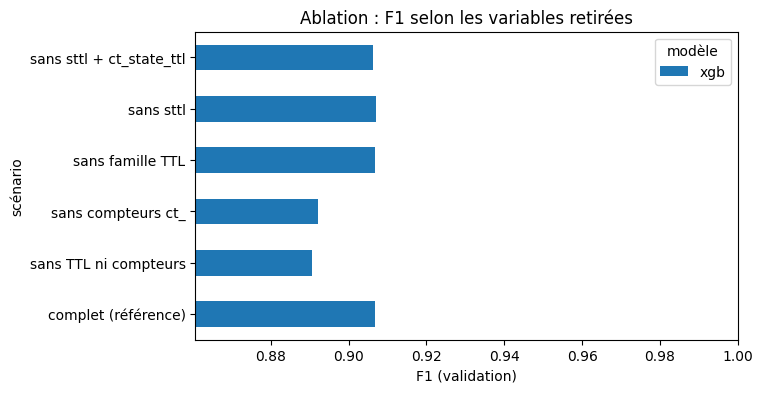

In [27]:
SEUIL = 0.0015      # ≈ 3 écarts-types de l'étape 15 (indicatif, à adapter)
ttl = ["sttl", "dttl", "ct_state_ttl"]
compteurs = [c for c in X_train.columns if c.startswith("ct_")]
scenarios = {
    "sans sttl": ["sttl"],
    "sans sttl + ct_state_ttl": ["sttl", "ct_state_ttl"],
    "sans famille TTL": ttl,
    "sans compteurs ct_": compteurs,
    "sans TTL ni compteurs": sorted(set(ttl + compteurs)),
}
MODELES = ["xgb"]     # d'abord XGBoost (rapide) ; ["xgb", "rf"] ajoute la forêt (~6 min par essai)

params = {"xgb": xgb_search.best_params_, "rf": rf_search.best_params_}
p_ref = {"xgb": p_val_xgb, "rf": p_val_rf}
lignes = []
for kind in MODELES:
    r = evaluate(y_val, p_ref[kind], best_threshold(y_val, p_ref[kind]), "complet", verbose=False)
    r.update({"modèle": kind, "scénario": "complet (référence)", "nb retirées": 0})
    lignes.append(r)
    for nom, retirees in scenarios.items():
        num_a = [c for c in num_cols if c not in retirees]
        m = build_model(kind, num_a, cat_cols, params[kind])      # mêmes réglages que le modèle complet
        m.fit(X_train[num_a + cat_cols], y_train)
        p = m.predict_proba(X_val[num_a + cat_cols])[:, 1]
        r = evaluate(y_val, p, best_threshold(y_val, p), nom, verbose=False)
        r.update({"modèle": kind, "scénario": nom, "nb retirées": len(retirees)})
        lignes.append(r)
        print("fait :", kind, "|", nom)

abl = pd.DataFrame(lignes)[["modèle", "scénario", "nb retirées", "PR-AUC", "précision", "rappel", "F1"]]
for kind in MODELES:
    masque = abl["modèle"] == kind
    ref = abl[masque & abl["scénario"].str.startswith("complet")].iloc[0]
    abl.loc[masque, "Δ PR-AUC"] = (abl.loc[masque, "PR-AUC"] - ref["PR-AUC"]).round(4)
    abl.loc[masque, "Δ F1"] = (abl.loc[masque, "F1"] - ref["F1"]).round(4)
abl["lecture"] = np.where(abl["Δ PR-AUC"].abs() < SEUIL, "pas de différence mesurable",
                          np.where(abl["Δ PR-AUC"] < 0, "perte", "gain"))
pd.set_option("display.width", 200)
print(abl.to_string(index=False))
abl.to_csv("results/ablation_elargie_validation.csv", index=False)

# Qu'est-ce qui a remplacé les variables retirées ? (dernier modèle, dernier scénario)
cols_a = num_a + cat_cols
Xt = m.named_steps["prep"].transform(X_val[cols_a])
perm = permutation_importance(m.named_steps["clf"], Xt, y_val, scoring="average_precision",
                              n_repeats=3, random_state=SEED, n_jobs=-1)
print("\nVariables les plus utilisées sans TTL ni compteurs :")
print(pd.Series(perm.importances_mean, index=cols_a).sort_values(ascending=False).head(8).round(4))

piv = abl.pivot(index="scénario", columns="modèle", values="F1")
piv.plot.barh(figsize=(7, 4)); plt.xlabel("F1 (validation)")
plt.xlim(max(0, piv.min().min() - 0.03), 1); plt.title("Ablation : F1 selon les variables retirées")
plt.savefig("figures/ablation_elargie.png", dpi=150, bbox_inches="tight"); plt.show()